In [7]:
""" 
Code for calculating the contrast planet-to-star ratio 
Calculate the Stellar Photon Emission at 505nm by each star condition
Calculate the planet Photon Emission at 505nm  by each planet condition 
Calculate the contrast planet-to-star 
Create a plot with the previous informations 

Required CSV files: 
stars.csv:
- SpT: Spectral type (e.g., G2V, K0V, M2V)
- Teff_K: Effective temperature in Kelvin
- R_Rsun: Stellar radius in solar radii 

planets.csv: 
- planet_name: Descriptive label (e.g., Earth-like, Ocean world)
- planet_type: Surface classification (Rocky Earth-like, Ocean world)
- coverage_pct: Percentage of visible disk covered by bioluminescent organisms (0-100)
- radius_Rearth: Planetary radius in Earth radii (e.g., 1.0, 2.0)

"""

' \nCode for calculating the contrast planet-to-star ratio \nCalculate the Stellar Photon Emission at 505nm by each star condition\nCalculate the planet Photon Emission at 505nm  by each planet condition \nCalculate the contrast planet-to-star \nCreate a plot with the previous informations \n\nRequired CSV files: \nstars.csv:\n- SpT: Spectral type (e.g., G2V, K0V, M2V)\n- Teff_K: Effective temperature in Kelvin\n- R_Rsun: Stellar radius in solar radii \n\nplanets.csv: \n- planet_name: Descriptive label (e.g., Earth-like, Ocean world)\n- planet_type: Surface classification (Rocky Earth-like, Ocean world)\n- coverage_pct: Percentage of visible disk covered by bioluminescent organisms (0-100)\n- radius_Rearth: Planetary radius in Earth radii (e.g., 1.0, 2.0)\n\n'

In [19]:
# Import libraries 
import os
import tkinter as tk
from tkinter import filedialog
import numpy as np
import pandas as pd
import astropy.units as u
import astropy.constants as const
from astropy.modeling.models import BlackBody
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.lines import Line2D


In [ ]:
# Create function for asking for the stellar CSV file 
def select_csv_file() -> str:
    root = tk.Tk()
    root.withdraw()  # Hide the empty root tkinter window
    root.attributes('-topmost', True)  # Bring the file dialog to the front
    
    file_path = filedialog.askopenfilename(
        title="Select your Stellar Parameters CSV file",
        filetypes=[("CSV files", "*.csv"), ("All files", "*.*")]
    )
    root.destroy()
    
    if not file_path:
        raise FileNotFoundError("No CSV file was selected. Execution cancelled.")
        
    return file_path


In [4]:
# Calculates total disk-integrated stellar photon emission (photons/s) at a target wavelength and bandpass assuming a blackbody spectrum.

def calc_star_photons(row: pd.Series, wavelength: u.Quantity, bandpass: u.Quantity) -> float:
    # 1. Compute blackbody surface radiance at the target wavelength
    bb = BlackBody(temperature=row['Teff_K'] * u.K)
    radiance = bb(wavelength)  # Units: erg / (cm^2 Hz s sr)
    
    # 2. Integrate over hemisphere (pi steradians) for Lambertian surface flux
    flux_nu = radiance * np.pi * u.sr
    
    # 3. Convert spectral flux density from per-Hz to per-nm
    flux_lam = flux_nu.to(
        u.erg / (u.cm**2 * u.s * u.nm),
        equivalencies=u.spectral_density(wavelength)
    )
    
    # 4. Calculate energy per photon at the target wavelength
    photon_energy = (const.h * const.c / wavelength).to(u.erg) / u.ph
    
    # 5. Convert energy flux to surface photon flux (photons / s / cm^2)
    surface_photon_flux = (flux_lam * bandpass / photon_energy).to(u.ph / (u.cm**2 * u.s))
    
    # 6. Multiply by the star's projected circular disk area (pi * R_star^2)
    r_cm = (row['R_Rsun'] * const.R_sun).to(u.cm)
    projected_area = np.pi * (r_cm ** 2)
    
    total_photons_s = (surface_photon_flux * projected_area).value
    return total_photons_s



In [23]:
# Calculate the photon flux from the star 
def star_calculation() -> pd.DataFrame:
    # --- Configuration Parameters ---
    TARGET_WAVELENGTH = 505 * u.nm   # Peak bioluminescence emission wavelength
    BANDPASS = 10 * u.nm             # Filter width (must match planetary emission bandpass)
    BENCHMARK_STARS = ['G2V', 'K0V', 'K5V', 'M0V', 'M2V', 'M5V']

    # --- Step 1: Load Stellar Data ---
    csv_path = select_csv_file("Select your Stellar Parameters CSV file")
    print(f"Loading stellar data from: {csv_path}")
    stars_df = pd.read_csv(csv_path)

    # Validate required columns
    required_cols = {'SpT', 'Teff_K', 'R_Rsun'}
    if not required_cols.issubset(stars_df.columns):
        raise ValueError(f"CSV must contain columns: {required_cols}")

    # --- Step 2: Flag Benchmark Stars for Figure 1 ---
    stars_df['is_benchmark'] = stars_df['SpT'].isin(BENCHMARK_STARS)

    # --- Step 3: Compute Stellar Photon Output ---
    stars_df['star_photons_s'] = stars_df.apply(
        calc_star_photons,
        axis=1,
        wavelength=TARGET_WAVELENGTH,
        bandpass=BANDPASS
    )

    # --- Step 4: Preview & Save Processed Table ---
    print("\nProcessed Stellar DataFrame:")
    print(stars_df.to_string(index=False))

    output_dir = os.path.dirname(csv_path)
    output_path = os.path.join(output_dir, "stars_processed_505nm.csv")
    stars_df.to_csv(output_path, index=False)
    print(f"\nSaved processed stellar table to: {output_path}")
    
    return stars_df  # Keeps stars_df in notebook memory!

# Call the function directly
stars_df = star_calculation()


Loading stellar data from: C:/Users/marin/Documents/Bioluminescence/contrast_ratio/stars.csv

Processed Stellar DataFrame:
SpT  Teff_K  R_Rsun  is_benchmark  star_photons_s
G2V    5770   1.012          True    3.257556e+42
G8V    5480   0.914         False    2.042774e+42
K0V    5270   0.813          True    1.312455e+42
K2V    5100   0.783         False    1.015878e+42
K5V    4440   0.701          True    3.541526e+41
K7V    4100   0.630         False    1.678971e+41
M0V    3850   0.588          True    9.311051e+40
M2V    3560   0.446          True    2.930833e+40
M4V    3210   0.274         False    4.621391e+39
M5V    3060   0.196          True    1.530419e+39

Saved processed stellar table to: C:/Users/marin/Documents/Bioluminescence/contrast_ratio\stars_processed_505nm.csv


In [8]:
# Creates a function asking for the planet CSV file 
def select_csv_file() -> str:
    root = tk.Tk()
    root.withdraw()
    root.attributes('-topmost', True)
    
    file_path = filedialog.askopenfilename(
        title="Select your Planetary Parameters CSV file",
        filetypes=[("CSV files", "*.csv"), ("All files", "*.*")]
    )
    root.destroy()
    
    if not file_path:
        raise FileNotFoundError("No CSV file was selected. Execution cancelled.")
        
    return file_path

In [9]:
# Creates function to calculate total disk-integrated planetary bioluminescent photon emission (photons/s).
    
def calc_planet_photons(row: pd.Series, bio_surface_flux: u.Quantity) -> float:
    """
    Formula:
        Total Photons/s = Surface Bioluminescent Flux * Projected Disk Area * Coverage Fraction
    """
    # 1. Convert planetary radius from Earth radii to centimeters
    r_cm = (row['radius_Rearth'] * const.R_earth).to(u.cm)
    
    # 2. Compute projected circular disk area (pi * R_planet^2)
    projected_area = np.pi * (r_cm ** 2)
    
    # 3. Apply fractional surface coverage (convert percentage to 0.0 - 1.0)
    coverage_fraction = row['coverage_pct'] / 100.0
    effective_emitting_area = projected_area * coverage_fraction
    
    # 4. Multiply surface photon flux by effective emitting area
    total_photons_s = (bio_surface_flux * effective_emitting_area).to(u.ph / u.s).value
    return total_photons_s


In [24]:
# Calculate the photon flux from the planet 
def planet_calculation() -> pd.DataFrame:
    # --- Biological Emission Parameters ---
    # Literature benchmark: 10^3 photons/s/bacterium * 10^8 cells/cm^3 * 100 cm (1 m) depth
    BIO_SURFACE_FLUX = 1e13 * (u.ph / (u.cm**2 * u.s))

    # --- Step 1: Load Planetary Data ---
    csv_path = select_csv_file("Select your Planetary Parameters CSV file")
    print(f"Loading planetary data from: {csv_path}")
    planets_df = pd.read_csv(csv_path)

    # Validate required columns
    required_cols = {'planet_name', 'planet_type', 'coverage_pct', 'radius_Rearth'}
    if not required_cols.issubset(planets_df.columns):
        raise ValueError(f"CSV must contain columns: {required_cols}")

    # --- Step 2: Compute Planetary Photon Output ---
    planets_df['planet_photons_s'] = planets_df.apply(
        calc_planet_photons,
        axis=1,
        bio_surface_flux=BIO_SURFACE_FLUX
    )

    # --- Step 3: Preview & Save Processed Table ---
    print("\nProcessed Planetary DataFrame:")
    print(planets_df.to_string(index=False))

    output_dir = os.path.dirname(csv_path)
    output_path = os.path.join(output_dir, "planets_processed_505nm.csv")
    planets_df.to_csv(output_path, index=False)
    print(f"\nSaved processed planetary table to: {output_path}")
    
    return planets_df  # Keeps planets_df in notebook memory!

# Call the function directly
planets_df = planet_calculation()


Loading planetary data from: C:/Users/marin/Documents/Bioluminescence/contrast_ratio/planets.csv

Processed Planetary DataFrame:
planet_name      planet_type  coverage_pct  radius_Rearth  planet_photons_s
 Earth-like Rocky Earth-like          1.00            1.0      1.278005e+29
 Earth-like Rocky Earth-like          1.00            2.0      5.112020e+29
 Earth-like Rocky Earth-like         42.57            1.0      5.440467e+30
 Earth-like Rocky Earth-like         42.57            2.0      2.176187e+31
 Earth-like Rocky Earth-like         71.00            1.0      9.073835e+30
 Earth-like Rocky Earth-like         71.00            2.0      3.629534e+31
Ocean world      Ocean world         57.14            1.0      7.302520e+30
Ocean world      Ocean world         57.14            2.0      2.921008e+31
Ocean world      Ocean world        100.00            1.0      1.278005e+31
Ocean world      Ocean world        100.00            2.0      5.112020e+31

Saved processed planetary table to

In [25]:
# Create function to ask for both CSV files 
def select_csv_file(dialog_title: str) -> str:
    """Opens a native file dialog window to select a processed CSV file."""
    root = tk.Tk()
    root.withdraw()
    root.attributes('-topmost', True)
    
    file_path = filedialog.askopenfilename(
        title=dialog_title,
        filetypes=[("CSV files", "*.csv"), ("All files", "*.*")]
    )
    root.destroy()
    
    if not file_path:
        raise FileNotFoundError(f"Selection cancelled for: {dialog_title}")
        
    return file_path


In [27]:
#Coss-Merge Both Stellar and Planets CSV in systems and calculate the contrast for that system 
def calculate_contrast() -> pd.DataFrame:
    # --- Step 1: Select Processed Stellar and Planetary CSVs ---
    stars_path = select_csv_file("Select 'stars_processed_505nm.csv'")
    planets_path = select_csv_file("Select 'planets_processed_505nm.csv'")

    stars_df = pd.read_csv(stars_path)
    planets_df = pd.read_csv(planets_path)

    # --- Step 2: Cross-Merge (Every Star x Every Planet Condition) ---
    systems_df = pd.merge(stars_df, planets_df, how='cross')

    # --- Step 3: Calculate Contrast Ratio (Raw & Base-10 Log) ---
    systems_df['contrast'] = systems_df['planet_photons_s'] / systems_df['star_photons_s']
    systems_df['log10_contrast'] = np.log10(systems_df['contrast'])

    # --- Step 4: Save Combined System Table ---
    output_dir = os.path.dirname(stars_path)
    merged_csv_path = os.path.join(output_dir, "system_contrasts_505nm.csv")
    systems_df.to_csv(merged_csv_path, index=False)
    print(f"Saved merged contrast table ({len(systems_df)} systems) to:\n  {merged_csv_path}\n")

    # Preview top rows with scientific notation for raw contrast and 2 decimals for log10
    with pd.option_context('display.float_format', '{:.3e}'.format):
        print(
            systems_df[[
                'SpT', 'Teff_K', 'planet_type', 'coverage_pct',
                'radius_Rearth', 'contrast', 'log10_contrast'
            ]].head(10).to_string(index=False)
        )
    return systems_df

systems_df = calculate_contrast()

Saved merged contrast table (100 systems) to:
  C:/Users/marin/Documents/Bioluminescence/contrast_ratio\system_contrasts_505nm.csv

SpT  Teff_K      planet_type  coverage_pct  radius_Rearth  contrast  log10_contrast
G2V    5770 Rocky Earth-like     1.000e+00      1.000e+00 3.923e-14      -1.341e+01
G2V    5770 Rocky Earth-like     1.000e+00      2.000e+00 1.569e-13      -1.280e+01
G2V    5770 Rocky Earth-like     4.257e+01      1.000e+00 1.670e-12      -1.178e+01
G2V    5770 Rocky Earth-like     4.257e+01      2.000e+00 6.680e-12      -1.118e+01
G2V    5770 Rocky Earth-like     7.100e+01      1.000e+00 2.785e-12      -1.156e+01
G2V    5770 Rocky Earth-like     7.100e+01      2.000e+00 1.114e-11      -1.095e+01
G2V    5770      Ocean world     5.714e+01      1.000e+00 2.242e-12      -1.165e+01
G2V    5770      Ocean world     5.714e+01      2.000e+00 8.967e-12      -1.105e+01
G2V    5770      Ocean world     1.000e+02      1.000e+00 3.923e-12      -1.141e+01
G2V    5770      Ocean world

In [28]:
# Renders a RGBA icon for either a 'Rock Earth-like' planet (blue ocean + green continents) or an 'Ocean world' (deep ocean gradient + subtle water bands). 
def create_planet_icon(planet_type: str, size_px: int = 120) -> np.ndarray:
    fig, ax = plt.subplots(figsize=(1.5, 1.5), dpi=size_px // 1.5)
    ax.set_xlim(-1.15, 1.15)
    ax.set_ylim(-1.15, 1.15)
    ax.set_aspect('equal')
    ax.axis('off')
    fig.patch.set_alpha(0.0)

    if 'ocean' in planet_type.lower():
        # Deep ocean base sphere
        ocean = patches.Circle((0, 0), 1.0, facecolor='#005b96', edgecolor='#011f4b', lw=2.5, zorder=1)
        ax.add_patch(ocean)
        # Subtle brighter pelagic water bands clipped to the sphere
        band1 = patches.Ellipse((-0.1, 0.25), 1.5, 0.55, angle=15, facecolor='#0086ad', alpha=0.65, zorder=2)
        band2 = patches.Ellipse((0.2, -0.3), 1.4, 0.45, angle=-10, facecolor='#00a8cc', alpha=0.55, zorder=2)
        band1.set_clip_path(ocean)
        band2.set_clip_path(ocean)
        ax.add_patch(band1)
        ax.add_patch(band2)
    else:
        # Earth-like ocean base sphere
        ocean = patches.Circle((0, 0), 1.0, facecolor='#1e88e5', edgecolor='#0d47a1', lw=2.5, zorder=1)
        ax.add_patch(ocean)
        # Stylized green continents clipped to the sphere
        cont1 = patches.Ellipse((-0.35, 0.35), 0.85, 0.65, angle=25, facecolor='#43a047', zorder=2)
        cont2 = patches.Ellipse((0.35, -0.15), 0.75, 0.90, angle=-20, facecolor='#2e7d32', zorder=2)
        cont3 = patches.Ellipse((-0.15, -0.55), 0.65, 0.45, angle=10, facecolor='#66bb6a', zorder=2)
        for c in (cont1, cont2, cont3):
            c.set_clip_path(ocean)
            ax.add_patch(c)

    # Subtle specular highlight for a 3D spherical look
    glint = patches.Circle((-0.32, 0.35), 0.28, facecolor='white', alpha=0.22, zorder=3)
    glint.set_clip_path(ocean)
    ax.add_patch(glint)

    fig.canvas.draw()
    rgba = np.asarray(fig.canvas.buffer_rgba()).copy()
    plt.close(fig)
    return rgba

Figure 1 successfully saved to: Figure1_Bioluminescence_Contrast.png


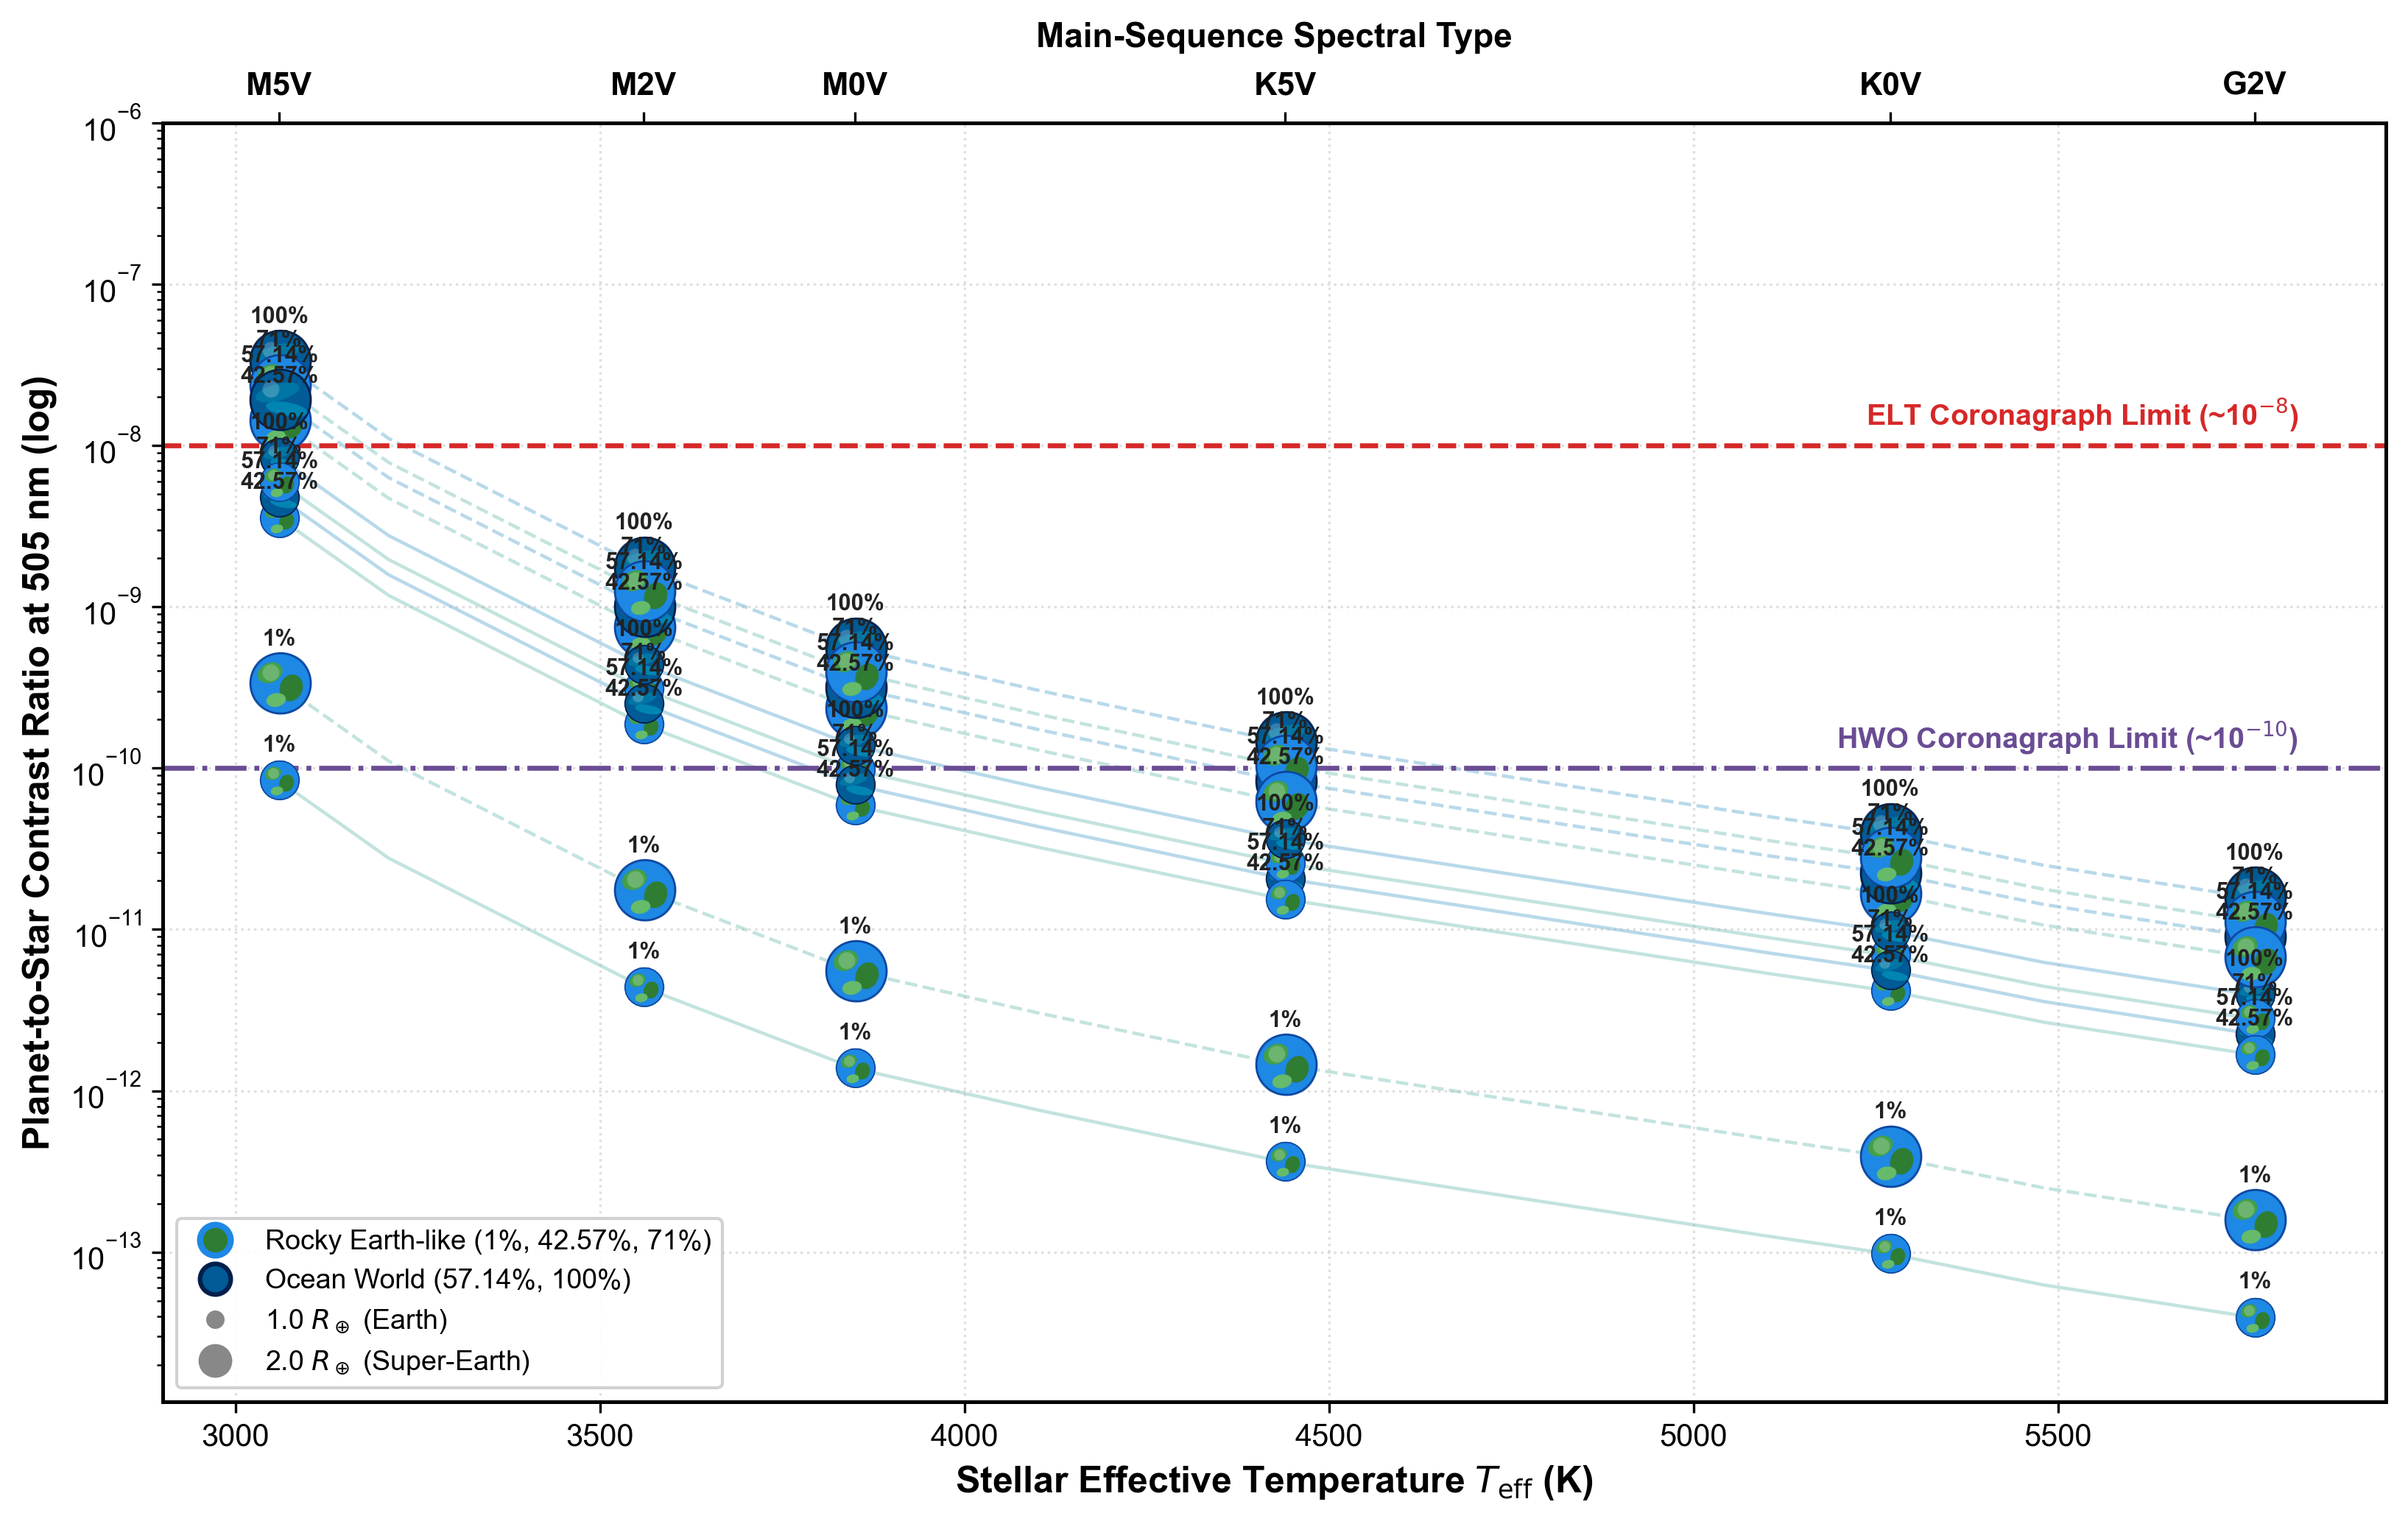

In [30]:
# Plot contrast Figure 1 from the merged star-planet contrast dataframe.
def plot_figure_1(systems_df: pd.DataFrame, output_path: str):
    plt.rcParams['font.sans-serif'] = 'Arial'
    plt.rcParams['axes.linewidth'] = 1.2

    fig, ax = plt.subplots(figsize=(11, 7), dpi=300)

    # Sort by temperature so trend lines connect smoothly from cool M to hot G stars
    systems_df = systems_df.sort_values('Teff_K')

    # --- 1. Plot Continuous Trend Lines Across All Stars ---
    grouped = systems_df.groupby(['planet_type', 'coverage_pct', 'radius_Rearth'])
    for (p_type, cov, rad), group in grouped:
        line_color = '#0077b6' if 'ocean' in p_type.lower() else '#2a9d8f'
        line_style = '-' if rad == 1.0 else '--'
        ax.plot(
            group['Teff_K'],
            group['contrast'],
            color=line_color,
            linestyle=line_style,
            linewidth=1.1,
            alpha=0.28,
            zorder=1
        )

    # --- 2. Stamp Custom Planet Icons at Benchmark Stars ---
    earth_img = create_planet_icon('Earth-like')
    ocean_img = create_planet_icon('Ocean world')

    benchmarks_df = systems_df[systems_df['is_benchmark'] == True].copy()

    for _, row in benchmarks_df.iterrows():
        icon_arr = ocean_img if 'ocean' in row['planet_type'].lower() else earth_img
        # Scale icon size by planetary radius (1.0 R_earth vs 2.0 R_earth)
        zoom_factor = 0.16 if row['radius_Rearth'] <= 1.0 else 0.25

        imagebox = OffsetImage(icon_arr, zoom=zoom_factor)
        ab = AnnotationBbox(
            imagebox,
            (row['Teff_K'], row['contrast']),
            frameon=False,
            zorder=4
        )
        ax.add_artist(ab)

        # Add clean percentage label slightly above each icon
        y_offset = 11 if row['radius_Rearth'] > 1.0 else 8
        cov_label = f"{row['coverage_pct']:g}%"
        ax.annotate(
            cov_label,
            xy=(row['Teff_K'], row['contrast']),
            xytext=(0, y_offset),
            textcoords='offset points',
            ha='center',
            va='bottom',
            fontsize=7.5,
            fontweight='bold',
            color='#222222',
            zorder=5
        )

    # --- 3. Add Instrument Coronagraph Contrast Limits ---
    # ELT (e.g., PCS / high-contrast imaging goal ~ 10^-8) & HWO (~ 10^-10)
    elt_limit = 1e-8
    hwo_limit = 1e-10

    ax.axhline(elt_limit, color='#d62828', linestyle='--', linewidth=1.6, zorder=2)
    ax.text(
        5830, elt_limit * 1.18,
        'ELT Coronagraph Limit (~10$^{-8}$)',
        color='#d62828', fontsize=9.5, fontweight='bold', ha='right', va='bottom'
    )

    ax.axhline(hwo_limit, color='#6a4c93', linestyle='-.', linewidth=1.6, zorder=2)
    ax.text(
        5830, hwo_limit * 1.18,
        'HWO Coronagraph Limit (~10$^{-10}$)',
        color='#6a4c93', fontsize=9.5, fontweight='bold', ha='right', va='bottom'
    )

    # --- 4. Format Axes & Top Spectral Type Labels ---
    ax.set_yscale('log')
    ax.set_xlim(2900, 5950)
    # Set generous Y limits around data and instrument thresholds
    y_min = min(systems_df['contrast'].min() * 0.3, 1e-12)
    y_max = max(systems_df['contrast'].max() * 4.0, 1e-6)
    ax.set_ylim(y_min, y_max)

    ax.set_xlabel('Stellar Effective Temperature $T_{\\mathrm{eff}}$ (K)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Planet-to-Star Contrast Ratio at 505 nm (log)', fontsize=12, fontweight='bold')
    ax.grid(True, which='major', linestyle=':', alpha=0.4)

    # Secondary top X-axis displaying Spectral Types (M5V -> G2V)
    ax_top = ax.twiny()
    ax_top.set_xlim(ax.get_xlim())
    bench_ticks = benchmarks_df[['SpT', 'Teff_K']].drop_duplicates().sort_values('Teff_K')
    ax_top.set_xticks(bench_ticks['Teff_K'])
    ax_top.set_xticklabels(bench_ticks['SpT'], fontsize=10.5, fontweight='bold')
    ax_top.set_xlabel('Main-Sequence Spectral Type', fontsize=11, fontweight='bold', labelpad=8)

    # --- 5. Clean Legend ---
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', label='Rocky Earth-like (1%, 42.57%, 71%)',
               markerfacecolor='#2e7d32', markeredgecolor='#1e88e5', markeredgewidth=2, markersize=10),
        Line2D([0], [0], marker='o', color='w', label='Ocean World (57.14%, 100%)',
               markerfacecolor='#005b96', markeredgecolor='#011f4b', markeredgewidth=1.5, markersize=10),
        Line2D([0], [0], marker='o', color='w', label='1.0 $R_\\oplus$ (Earth)',
               markerfacecolor='#888888', markersize=7),
        Line2D([0], [0], marker='o', color='w', label='2.0 $R_\\oplus$ (Super-Earth)',
               markerfacecolor='#888888', markersize=12),
    ]
    ax.legend(handles=legend_elements, loc='lower left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9)

    plt.tight_layout()
    plt.savefig(output_path, dpi=300)
    print(f"Figure 1 successfully saved to: {output_path}")
    plt.show()

plot_figure_1(systems_df, "Figure1_Bioluminescence_Contrast.png")


Publication-ready Figure 1 saved to: Figure1_Bioluminescence_Contrast_Final.png


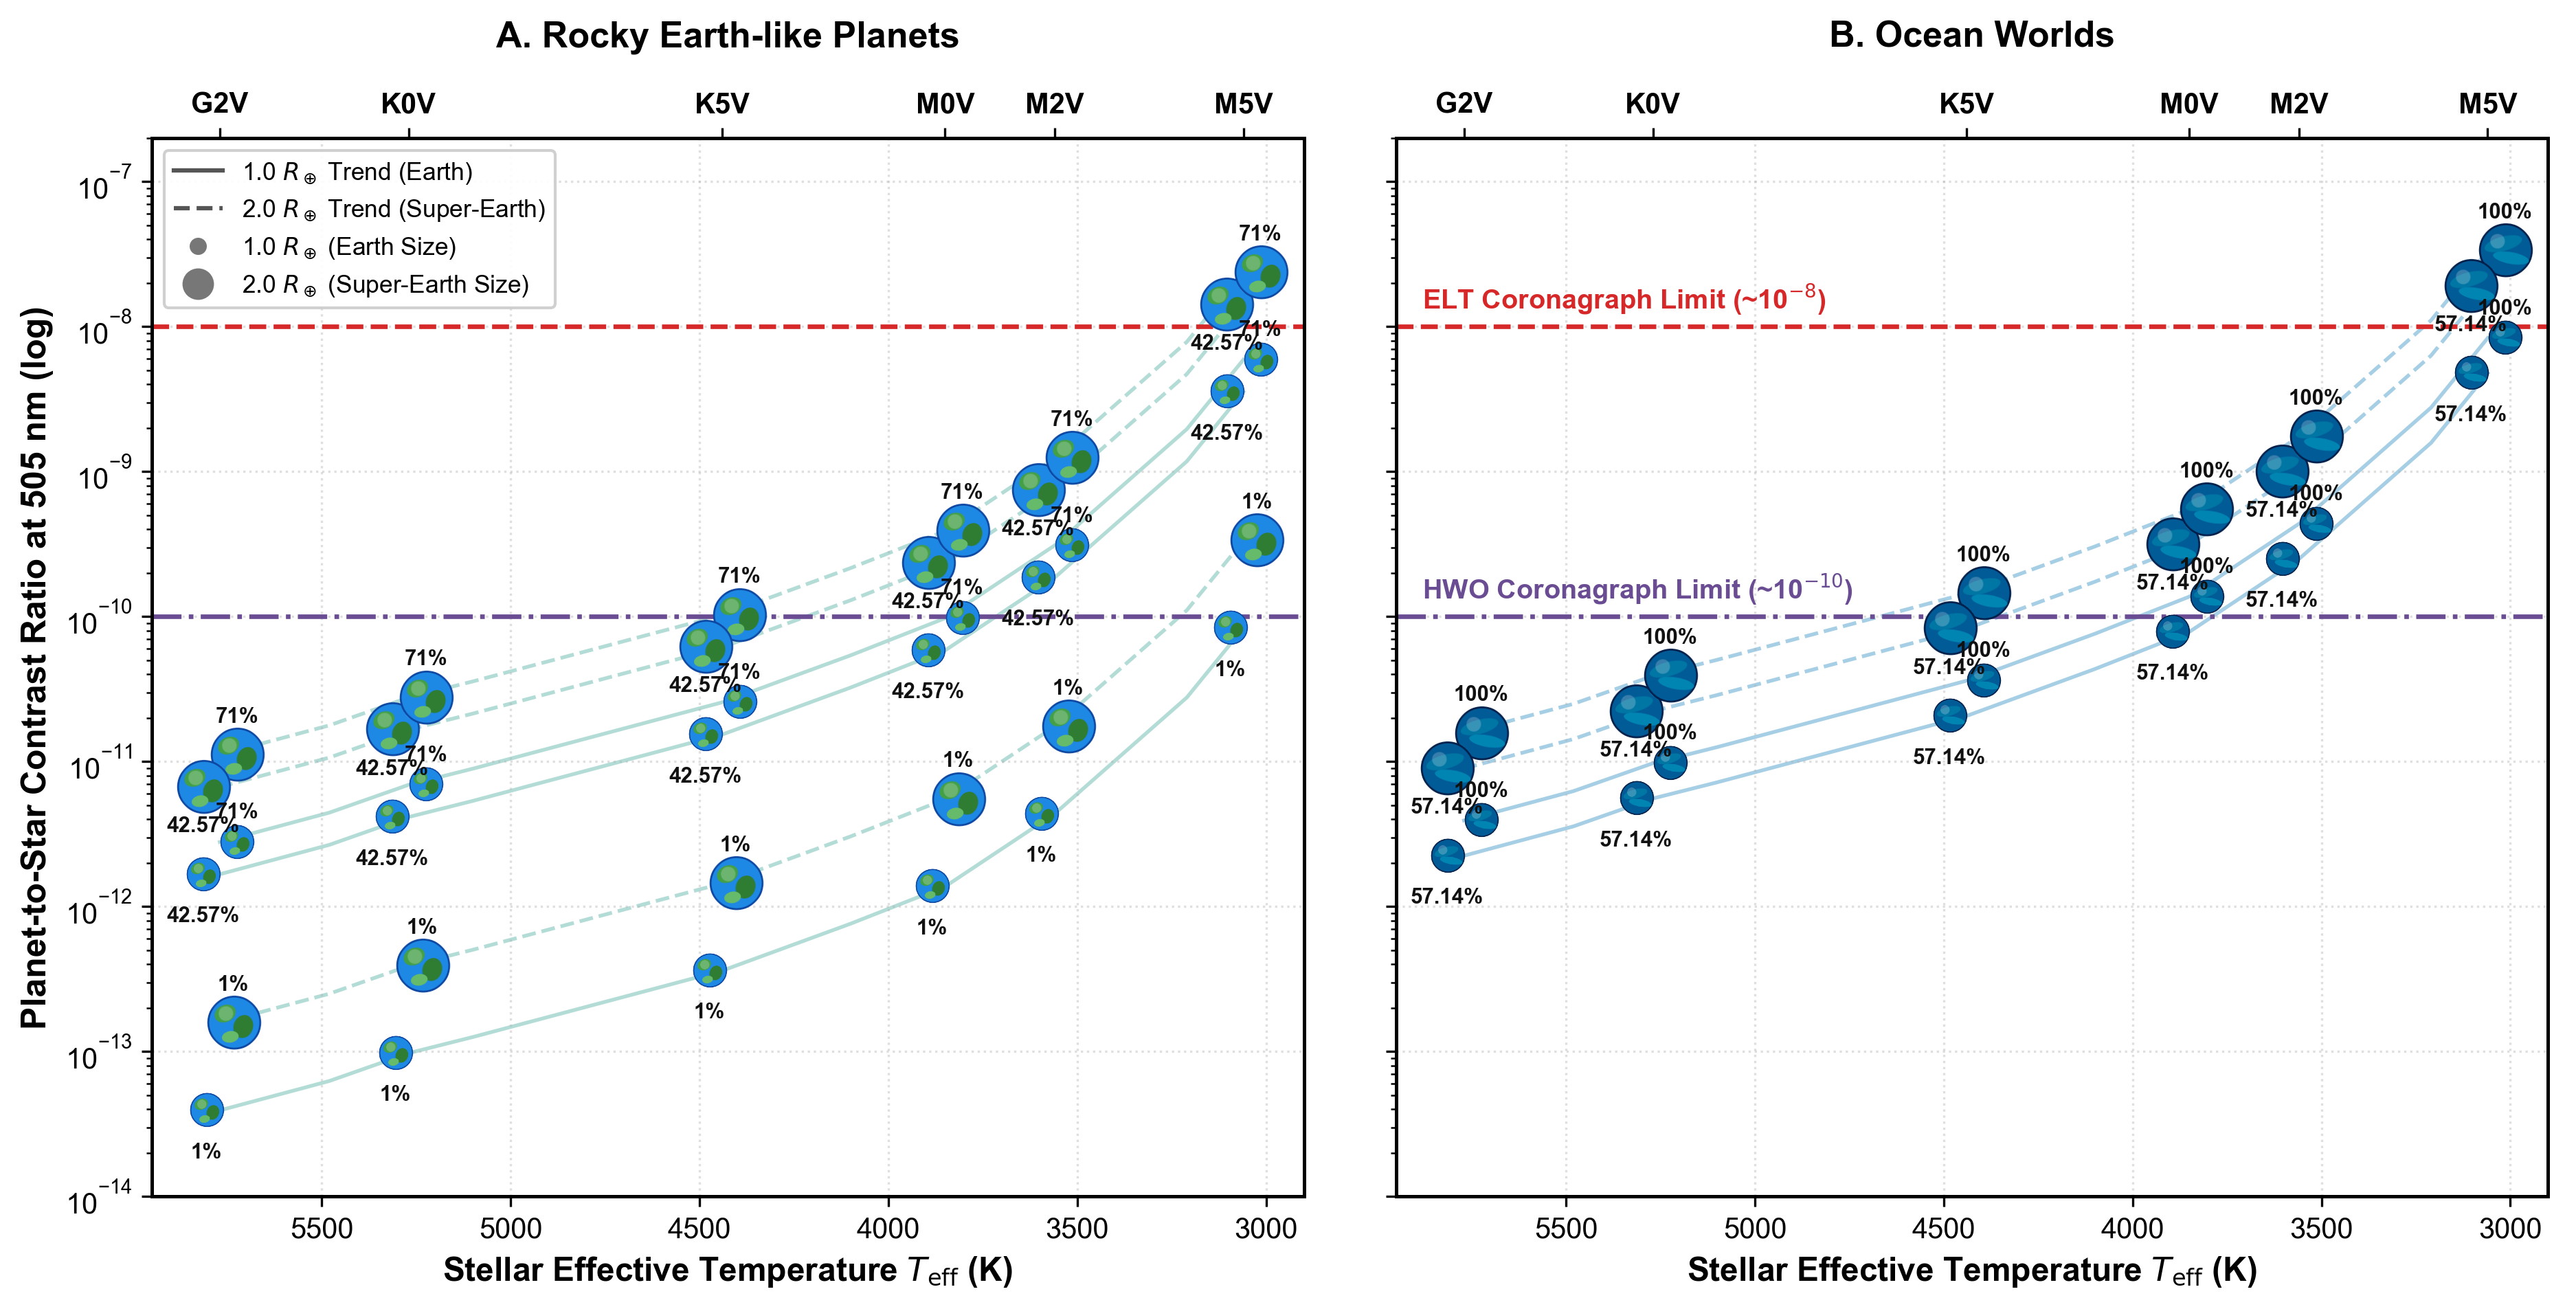

In [33]:
# Create 2 subplots (2 panel figure) 
# Invert the X axis and thight the Y axis cap 
def plot_figure_1(systems_df: pd.DataFrame, output_path: str):
    """
    Generates a publication-ready two-panel Figure 1:
      - Panel A: Rocky Earth-like planets (1%, 42.57%, 71%)
      - Panel B: Ocean worlds (57.14%, 100%)
    """
    plt.rcParams['font.sans-serif'] = 'Arial'
    plt.rcParams['axes.linewidth'] = 1.2

    fig, axes = plt.subplots(1, 2, figsize=(15, 6.8), dpi=300, sharey=True)
    plt.subplots_adjust(wspace=0.08)

    systems_df = systems_df.sort_values('Teff_K')
    earth_img = create_planet_icon('Earth-like')
    ocean_img = create_planet_icon('Ocean world')

    panels = [
        {
            'ax': axes[0],
            'title': 'A. Rocky Earth-like Planets',
            'filter_str': 'earth',
            'icon': earth_img,
            'line_color': '#2a9d8f'
        },
        {
            'ax': axes[1],
            'title': 'B. Ocean Worlds',
            'filter_str': 'ocean',
            'icon': ocean_img,
            'line_color': '#0077b6'
        }
    ]

    for panel in panels:
        ax = panel['ax']
        sub_df = systems_df[systems_df['planet_type'].str.lower().str.contains(panel['filter_str'])].copy()

        # --- 1. Plot Continuous Trend Lines ---
        grouped = sub_df.groupby(['coverage_pct', 'radius_Rearth'])
        for (cov, rad), group in grouped:
            line_style = '-' if rad == 1.0 else '--'
            ax.plot(
                group['Teff_K'],
                group['contrast'],
                color=panel['line_color'],
                linestyle=line_style,
                linewidth=1.3,
                alpha=0.35,
                zorder=1
            )

        # --- 2. Stamp Planet Icons & Non-Overlapping Percentage Labels ---
        benchmarks_df = sub_df[sub_df['is_benchmark'] == True].copy()

        for _, row in benchmarks_df.iterrows():
            is_super = row['radius_Rearth'] > 1.0
            cov = row['coverage_pct']
            zoom_factor = 0.23 if is_super else 0.145

            # Separate close coverage pairs horizontally so icons never overlap vertically
            if cov in [71.0, 100.0]:
                x_pos = row['Teff_K'] - 45  # Nudge slightly right (toward cooler T)
                y_offset = 10 if is_super else 7
                va_align = 'bottom'
            elif cov in [42.57, 57.14]:
                x_pos = row['Teff_K'] + 45  # Nudge slightly left (toward hotter T)
                y_offset = -10 if is_super else -11
                va_align = 'top'
            else:  # 1% coverage
                x_pos = row['Teff_K'] - 35 if is_super else row['Teff_K'] + 35
                y_offset = 10 if is_super else -11
                va_align = 'bottom' if is_super else 'top'

            imagebox = OffsetImage(panel['icon'], zoom=zoom_factor)
            ab = AnnotationBbox(
                imagebox,
                (x_pos, row['contrast']),
                frameon=False,
                zorder=4
            )
            ax.add_artist(ab)

            cov_label = f"{cov:g}%"
            ax.annotate(
                cov_label,
                xy=(x_pos, row['contrast']),
                xytext=(0, y_offset),
                textcoords='offset points',
                ha='center',
                va=va_align,
                fontsize=7.5,
                fontweight='bold',
                color='#111111',
                zorder=5
            )

        # --- 3. Instrument Coronagraph Limits ---
        elt_limit = 1e-8
        hwo_limit = 1e-10

        ax.axhline(elt_limit, color='#d62828', linestyle='--', linewidth=1.6, zorder=2)
        ax.axhline(hwo_limit, color='#6a4c93', linestyle='-.', linewidth=1.6, zorder=2)

        # Place limit text cleanly in the empty upper-left region of Panel B
        if panel['filter_str'] == 'ocean':
            ax.text(
                5880, elt_limit * 1.18,
                'ELT Coronagraph Limit (~10$^{-8}$)',
                color='#d62828', fontsize=9.5, fontweight='bold', ha='left', va='bottom'
            )
            ax.text(
                5880, hwo_limit * 1.18,
                'HWO Coronagraph Limit (~10$^{-10}$)',
                color='#6a4c93', fontsize=9.5, fontweight='bold', ha='left', va='bottom'
            )

        # --- 4. Format Axes (Hot G2V on Left -> Cool M5V on Right, Y capped at 2e-7) ---
        ax.set_yscale('log')
        ax.set_xlim(5950, 2900)
        y_min = min(systems_df['contrast'].min() * 0.3, 1e-14)
        ax.set_ylim(y_min, 2e-7)

        ax.set_xlabel('Stellar Effective Temperature $T_{\\mathrm{eff}}$ (K)', fontsize=11.5, fontweight='bold')
        ax.grid(True, which='major', linestyle=':', alpha=0.4)

        # Top X-axis for Spectral Types
        ax_top = ax.twiny()
        ax_top.set_xlim(ax.get_xlim())
        bench_ticks = benchmarks_df[['SpT', 'Teff_K']].drop_duplicates().sort_values('Teff_K', ascending=False)
        ax_top.set_xticks(bench_ticks['Teff_K'])
        ax_top.set_xticklabels(bench_ticks['SpT'], fontsize=10, fontweight='bold')
        ax_top.set_title(panel['title'], fontsize=12.5, fontweight='bold', pad=16)

    # Shared Y-axis label on left panel only
    axes[0].set_ylabel('Planet-to-Star Contrast Ratio at 505 nm (log)', fontsize=12, fontweight='bold')

    # --- 5. Clean Legend on Panel A ---
    legend_elements = [
        Line2D([0], [0], color='#555555', linestyle='-', lw=1.5, label='1.0 $R_\\oplus$ Trend (Earth)'),
        Line2D([0], [0], color='#555555', linestyle='--', lw=1.5, label='2.0 $R_\\oplus$ Trend (Super-Earth)'),
        Line2D([0], [0], marker='o', color='w', label='1.0 $R_\\oplus$ (Earth Size)',
               markerfacecolor='#777777', markersize=7),
        Line2D([0], [0], marker='o', color='w', label='2.0 $R_\\oplus$ (Super-Earth Size)',
               markerfacecolor='#777777', markersize=12),
    ]
    axes[0].legend(handles=legend_elements, loc='upper left', frameon=True, facecolor='white', framealpha=0.92, fontsize=8.5)

    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"Publication-ready Figure 1 saved to: {output_path}")
    plt.show()

# Run the updated plot
plot_figure_1(systems_df, "Figure1_Bioluminescence_Contrast_Final.png")


Publication-ready Figure 1 saved to: Figure1_Bioluminescence_Contrast_Final.png


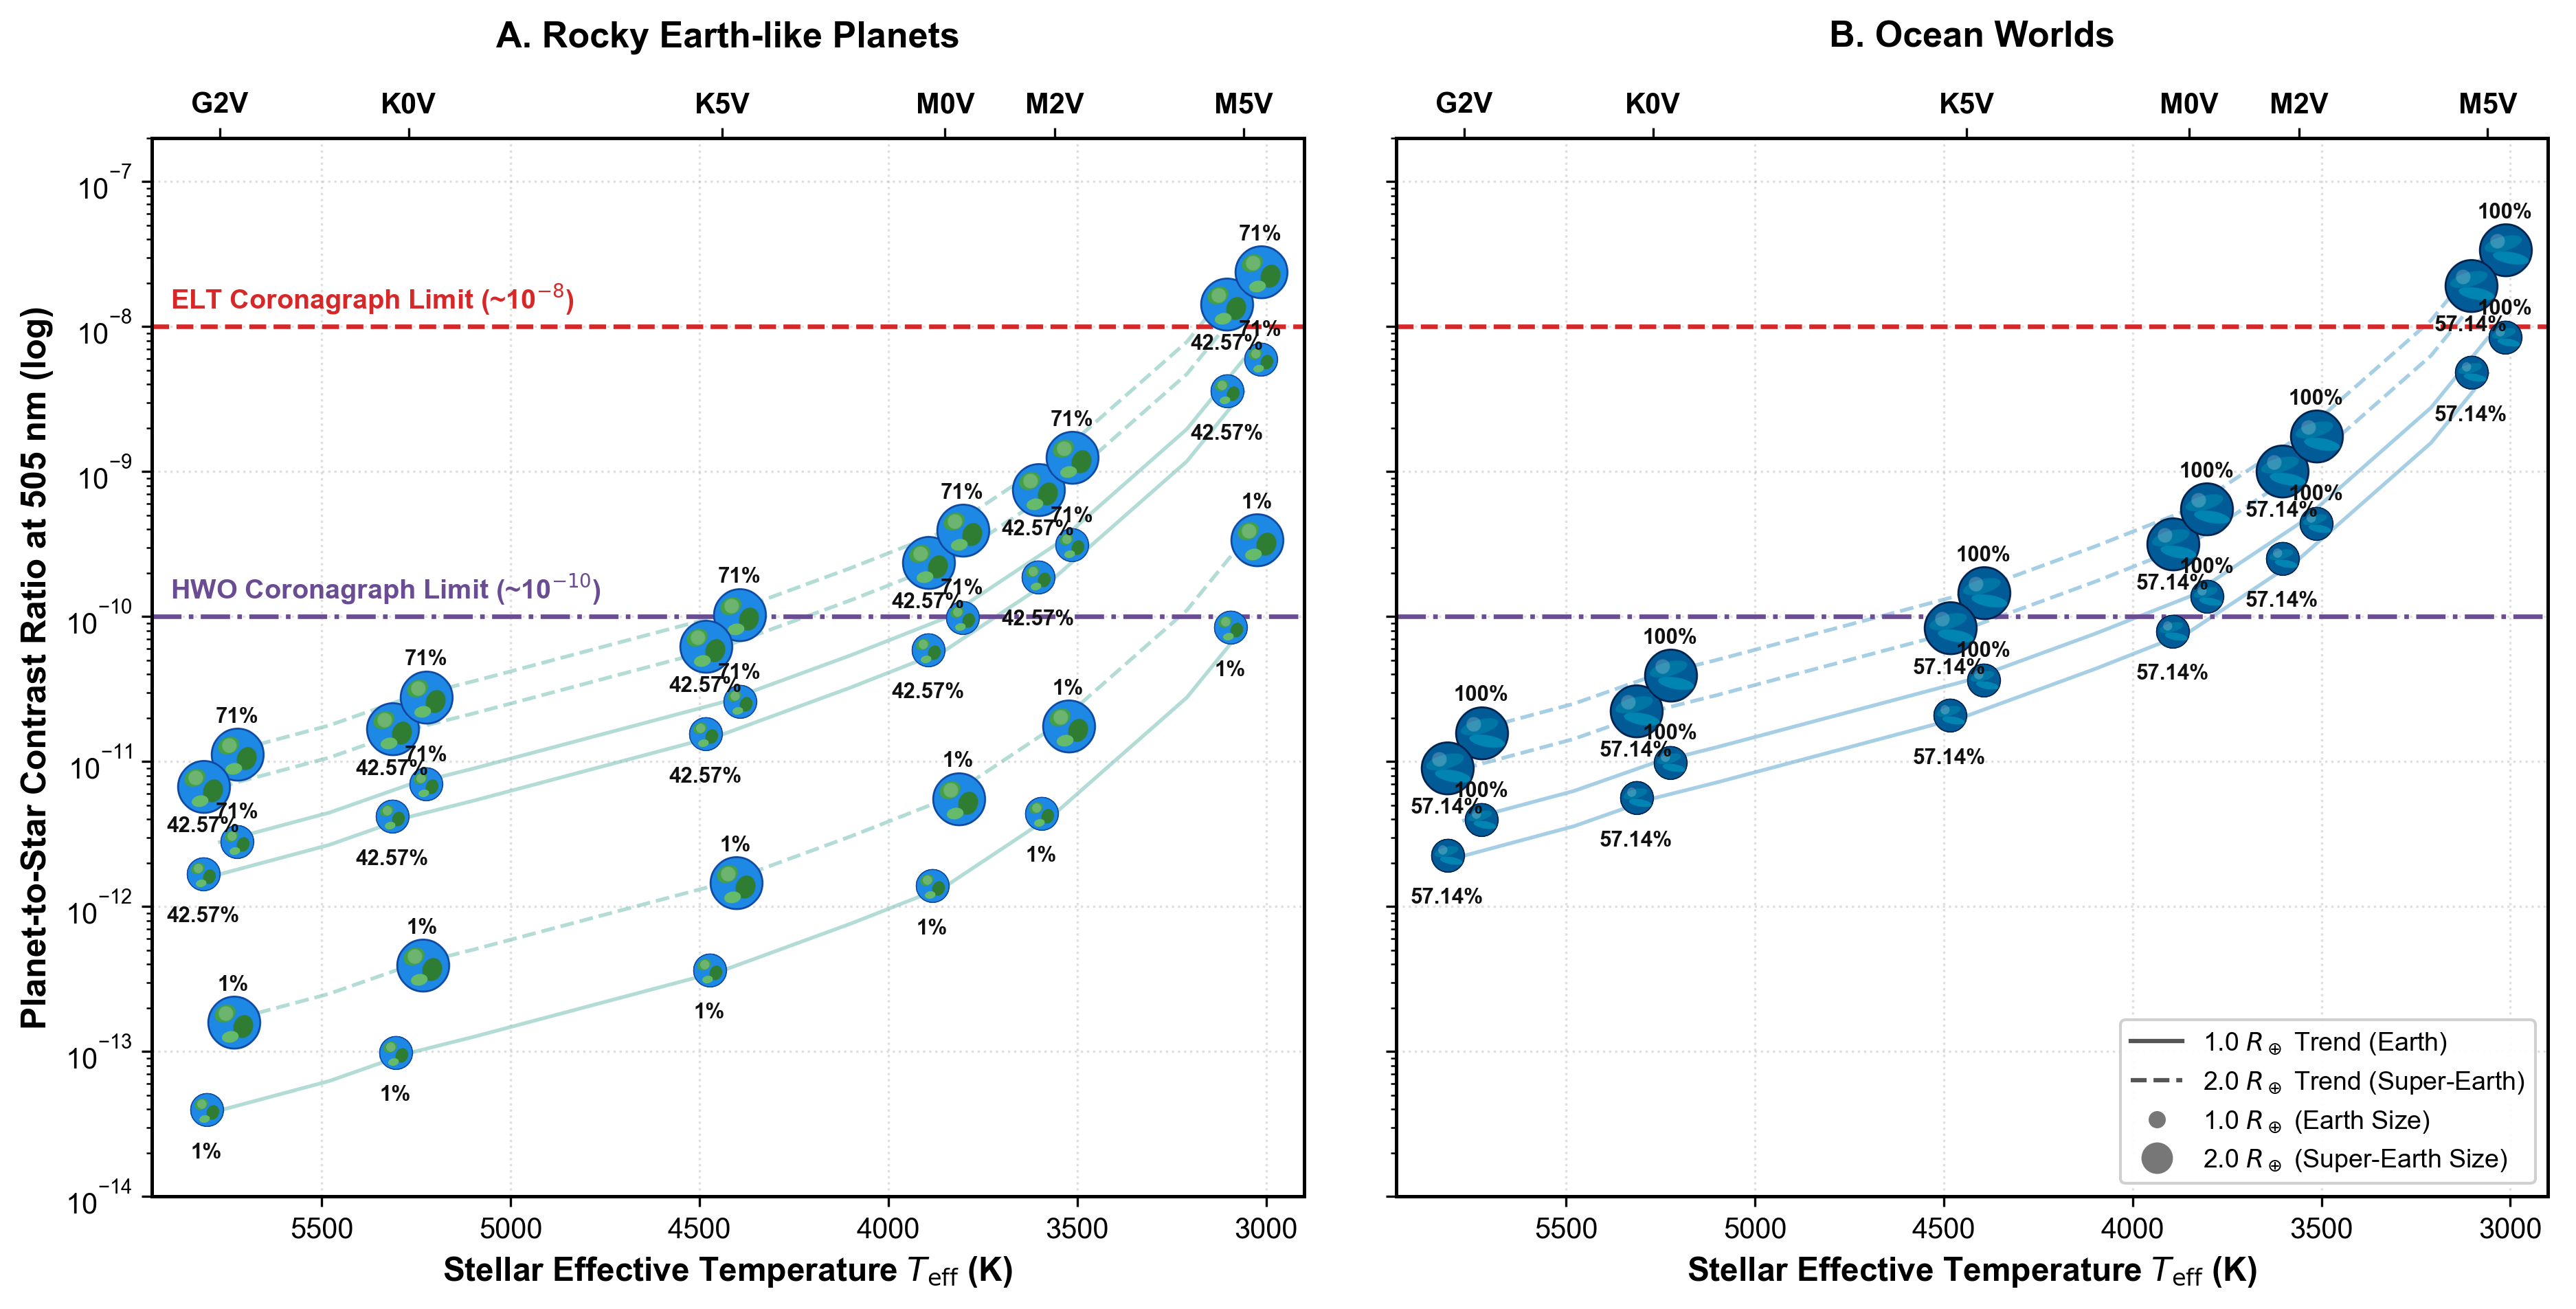

In [34]:
# Changing label sides 
def plot_figure_1(systems_df: pd.DataFrame, output_path: str):
    """
    Generates a publication-ready two-panel Figure 1:
      - Panel A: Rocky Earth-like planets (1%, 42.57%, 71%) with ELT/HWO labels on far left
      - Panel B: Ocean worlds (57.14%, 100%) with legend in the bottom-right corner
    """
    plt.rcParams['font.sans-serif'] = 'Arial'
    plt.rcParams['axes.linewidth'] = 1.2

    fig, axes = plt.subplots(1, 2, figsize=(15, 6.8), dpi=300, sharey=True)
    plt.subplots_adjust(wspace=0.08)

    systems_df = systems_df.sort_values('Teff_K')
    earth_img = create_planet_icon('Earth-like')
    ocean_img = create_planet_icon('Ocean world')

    panels = [
        {
            'ax': axes[0],
            'title': 'A. Rocky Earth-like Planets',
            'filter_str': 'earth',
            'icon': earth_img,
            'line_color': '#2a9d8f'
        },
        {
            'ax': axes[1],
            'title': 'B. Ocean Worlds',
            'filter_str': 'ocean',
            'icon': ocean_img,
            'line_color': '#0077b6'
        }
    ]

    for panel in panels:
        ax = panel['ax']
        sub_df = systems_df[systems_df['planet_type'].str.lower().str.contains(panel['filter_str'])].copy()

        # --- 1. Plot Continuous Trend Lines ---
        grouped = sub_df.groupby(['coverage_pct', 'radius_Rearth'])
        for (cov, rad), group in grouped:
            line_style = '-' if rad == 1.0 else '--'
            ax.plot(
                group['Teff_K'],
                group['contrast'],
                color=panel['line_color'],
                linestyle=line_style,
                linewidth=1.3,
                alpha=0.35,
                zorder=1
            )

        # --- 2. Stamp Planet Icons & Non-Overlapping Percentage Labels ---
        benchmarks_df = sub_df[sub_df['is_benchmark'] == True].copy()

        for _, row in benchmarks_df.iterrows():
            is_super = row['radius_Rearth'] > 1.0
            cov = row['coverage_pct']
            zoom_factor = 0.23 if is_super else 0.145

            # Separate close coverage pairs horizontally so icons never overlap vertically
            if cov in [71.0, 100.0]:
                x_pos = row['Teff_K'] - 45
                y_offset = 10 if is_super else 7
                va_align = 'bottom'
            elif cov in [42.57, 57.14]:
                x_pos = row['Teff_K'] + 45
                y_offset = -10 if is_super else -11
                va_align = 'top'
            else:  # 1% coverage
                x_pos = row['Teff_K'] - 35 if is_super else row['Teff_K'] + 35
                y_offset = 10 if is_super else -11
                va_align = 'bottom' if is_super else 'top'

            imagebox = OffsetImage(panel['icon'], zoom=zoom_factor)
            ab = AnnotationBbox(
                imagebox,
                (x_pos, row['contrast']),
                frameon=False,
                zorder=4
            )
            ax.add_artist(ab)

            cov_label = f"{cov:g}%"
            ax.annotate(
                cov_label,
                xy=(x_pos, row['contrast']),
                xytext=(0, y_offset),
                textcoords='offset points',
                ha='center',
                va=va_align,
                fontsize=7.5,
                fontweight='bold',
                color='#111111',
                zorder=5
            )

        # --- 3. Instrument Coronagraph Limits ---
        elt_limit = 1e-8
        hwo_limit = 1e-10

        ax.axhline(elt_limit, color='#d62828', linestyle='--', linewidth=1.6, zorder=2)
        ax.axhline(hwo_limit, color='#6a4c93', linestyle='-.', linewidth=1.6, zorder=2)

        # Place ELT & HWO limit labels on the far left of Panel A
        if panel['filter_str'] == 'earth':
            ax.text(
                5900, elt_limit * 1.18,
                'ELT Coronagraph Limit (~10$^{-8}$)',
                color='#d62828', fontsize=9.5, fontweight='bold', ha='left', va='bottom'
            )
            ax.text(
                5900, hwo_limit * 1.18,
                'HWO Coronagraph Limit (~10$^{-10}$)',
                color='#6a4c93', fontsize=9.5, fontweight='bold', ha='left', va='bottom'
            )

        # --- 4. Format Axes (Hot G2V on Left -> Cool M5V on Right, Y capped at 2e-7) ---
        ax.set_yscale('log')
        ax.set_xlim(5950, 2900)
        y_min = min(systems_df['contrast'].min() * 0.3, 1e-14)
        ax.set_ylim(y_min, 2e-7)

        ax.set_xlabel('Stellar Effective Temperature $T_{\\mathrm{eff}}$ (K)', fontsize=11.5, fontweight='bold')
        ax.grid(True, which='major', linestyle=':', alpha=0.4)

        # Top X-axis for Spectral Types
        ax_top = ax.twiny()
        ax_top.set_xlim(ax.get_xlim())
        bench_ticks = benchmarks_df[['SpT', 'Teff_K']].drop_duplicates().sort_values('Teff_K', ascending=False)
        ax_top.set_xticks(bench_ticks['Teff_K'])
        ax_top.set_xticklabels(bench_ticks['SpT'], fontsize=10, fontweight='bold')
        ax_top.set_title(panel['title'], fontsize=12.5, fontweight='bold', pad=16)

    # Shared Y-axis label on left panel only
    axes[0].set_ylabel('Planet-to-Star Contrast Ratio at 505 nm (log)', fontsize=12, fontweight='bold')

    # --- 5. Clean Legend in the Bottom-Right Corner of Panel B ---
    legend_elements = [
        Line2D([0], [0], color='#555555', linestyle='-', lw=1.5, label='1.0 $R_\\oplus$ Trend (Earth)'),
        Line2D([0], [0], color='#555555', linestyle='--', lw=1.5, label='2.0 $R_\\oplus$ Trend (Super-Earth)'),
        Line2D([0], [0], marker='o', color='w', label='1.0 $R_\\oplus$ (Earth Size)',
               markerfacecolor='#777777', markersize=7),
        Line2D([0], [0], marker='o', color='w', label='2.0 $R_\\oplus$ (Super-Earth Size)',
               markerfacecolor='#777777', markersize=12),
    ]
    axes[1].legend(handles=legend_elements, loc='lower right', frameon=True, facecolor='white', framealpha=0.92, fontsize=9)

    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    print(f"Publication-ready Figure 1 saved to: {output_path}")
    plt.show()

# Run the updated plot
plot_figure_1(systems_df, "Figure1_Bioluminescence_Contrast_Final.png")


In [37]:
# For an interative plot 

# Import new libraries 
import base64
from io import BytesIO
from scipy.interpolate import PchipInterpolator
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from PIL import Image

In [41]:
# Creating an interative plot 
def rgba_to_base64_uri(rgba_array: np.ndarray) -> str:
    """Converts an RGBA numpy array (from create_planet_icon) into a Plotly-compatible image URI."""
    img = Image.fromarray(rgba_array.astype('uint8'), 'RGBA')
    buffer = BytesIO()
    img.save(buffer, format='PNG')
    encoded = base64.b64encode(buffer.getvalue()).decode('utf-8')
    return f"data:image/png;base64,{encoded}"


def plot_interactive_figure_1(systems_df: pd.DataFrame, html_output: str = "Figure1_Interactive.html"):
    """
    Creates a smooth, interactive two-panel Plotly version of Figure 1 with
    PCHIP-interpolated curves, hover tooltips, and embedded Earth/Ocean icons.
    """
    systems_df = systems_df.sort_values('Teff_K')

    # Convert your custom Matplotlib planet icons into base64 strings for Plotly
    earth_uri = rgba_to_base64_uri(create_planet_icon('Earth-like', size_px=150))
    ocean_uri = rgba_to_base64_uri(create_planet_icon('Ocean world', size_px=150))

    fig = make_subplots(
        rows=1, cols=2,
        shared_yaxes=True,
        horizontal_spacing=0.05,
        subplot_titles=("<b>A. Rocky Earth-like Planets</b>", "<b>B. Ocean Worlds</b>")
    )

    panels = [
        {'col': 1, 'filter_str': 'earth', 'uri': earth_uri, 'color': '#2a9d8f', 'xref': 'x', 'yref': 'y'},
        {'col': 2, 'filter_str': 'ocean', 'uri': ocean_uri, 'color': '#0077b6', 'xref': 'x2', 'yref': 'y2'}
    ]

    for panel in panels:
        col = panel['col']
        sub_df = systems_df[systems_df['planet_type'].str.lower().str.contains(panel['filter_str'])].copy()

        # --- 1. Smooth PCHIP Interpolated Trend Lines ---
        for (cov, rad), group in sub_df.groupby(['coverage_pct', 'radius_Rearth']):
            group = group.sort_values('Teff_K')
            teff_vals = group['Teff_K'].values
            log_c_vals = np.log10(group['contrast'].values)

            # Smooth 200-point curve in log-space (eliminates jagged line segments)
            teff_smooth = np.linspace(teff_vals.min(), teff_vals.max(), 200)
            interpolator = PchipInterpolator(teff_vals, log_c_vals)
            contrast_smooth = 10 ** interpolator(teff_smooth)

            dash_style = 'solid' if rad == 1.0 else 'dash'
            rad_label = f"{rad:g} R⊕"

            fig.add_trace(
                go.Scatter(
                    x=teff_smooth,
                    y=contrast_smooth,
                    mode='lines',
                    line=dict(color=panel['color'], width=2, dash=dash_style),
                    opacity=0.45,
                    name=f"{rad_label} ({cov:g}%)",
                    legendgroup=rad_label,
                    showlegend=(col == 1 and cov in [1.0, 71.0]),
                    hoverinfo='skip'
                ),
                row=1, col=col
            )

        # --- 2. Benchmark Interactive Hover Points + Custom Planet Icons ---
        benchmarks_df = sub_df[sub_df['is_benchmark'] == True].copy()

        for _, row in benchmarks_df.iterrows():
            is_super = row['radius_Rearth'] > 1.0
            cov = row['coverage_pct']

            # Horizontal micro-offset to prevent overlap
            if cov in [71.0, 100.0]:
                x_pos = row['Teff_K'] - 45
                text_pos = "top center"
            elif cov in [42.57, 57.14]:
                x_pos = row['Teff_K'] + 45
                text_pos = "bottom center"
            else:
                x_pos = row['Teff_K'] - 35 if is_super else row['Teff_K'] + 35
                text_pos = "top center" if is_super else "bottom center"

            # Invisible scatter marker for rich interactive hover tooltips & percentage text
            fig.add_trace(
                go.Scatter(
                    x=[x_pos],
                    y=[row['contrast']],
                    mode='markers+text',
                    marker=dict(size=18 if is_super else 12, opacity=0),
                    text=[f"<b>{cov:g}%</b>"],
                    textposition=text_pos,
                    textfont=dict(size=10, color='#111111'),
                    showlegend=False,
                    hovertemplate=(
                        f"<b>{row['SpT']} ({row['Teff_K']} K)</b><br>"
                        f"Type: {row['planet_type']}<br>"
                        f"Radius: {row['radius_Rearth']:g} R⊕<br>"
                        f"Coverage: {cov:g}%<br>"
                        f"Contrast: <b>{row['contrast']:.2e}</b><extra></extra>"
                    )
                ),
                row=1, col=col
            )

            # Stamp the custom Earth or Ocean icon at the exact log coordinate
            icon_sizex = 210 if is_super else 135
            icon_sizey = 0.28 if is_super else 0.18  # In log10 units

            fig.add_layout_image(
                dict(
                    source=panel['uri'],
                    xref=panel['xref'],
                    yref=panel['yref'],
                    x=x_pos,
                    y=np.log10(row['contrast']),
                    sizex=icon_sizex,
                    sizey=icon_sizey,
                    xanchor="center",
                    yanchor="middle",
                    layer="above"
                )
            )

        # --- 3. Instrument Threshold Lines ---
        fig.add_hline(y=1e-8, line_dash="dash", line_color="#d62828", line_width=2, row=1, col=col)
        fig.add_hline(y=1e-10, line_dash="dashdot", line_color="#6a4c93", line_width=2, row=1, col=col)

    # Add ELT & HWO text annotations on the far left of Panel A
    fig.add_annotation(
        x=5880, y=np.log10(1.4e-8), xref="x", yref="y",
        text="<b>ELT Coronagraph Limit (~10⁻⁸)</b>",
        showarrow=False, font=dict(color="#d62828", size=12), xanchor="left"
    )
    fig.add_annotation(
        x=5880, y=np.log10(1.4e-10), xref="x", yref="y",
        text="<b>HWO Coronagraph Limit (~10⁻¹⁰)</b>",
        showarrow=False, font=dict(color="#6a4c93", size=12), xanchor="left"
    )

    # --- 4. Clean Publication Layout ---
    y_min_log = np.log10(min(systems_df['contrast'].min() * 0.3, 1e-14))
    y_max_log = np.log10(2e-7)

    fig.update_yaxes(
        type="log",
        range=[y_min_log, y_max_log],
        exponentformat="power",
        showgrid=True,
        gridcolor="rgba(0,0,0,0.08)",
        linecolor="black",
        mirror=True
    )
    fig.update_yaxes(title_text="<b>Planet-to-Star Contrast Ratio at 505 nm (log)</b>", row=1, col=1)
    
    for c in range(1, 3):
        fig.update_xaxes(
            range=tuple((5950, 2900)),  # Reversed: G2V -> M5V
            title_text="<b>Stellar Effective Temperature T_eff (K)</b>",
            showgrid=True,
            gridcolor="rgba(0,0,0,0.08)",
            linecolor="black",
            mirror=True,
            row=1, col=c
        )

    fig.update_layout(
        template="simple_white",
        width=1250,
        height=620,
        font=dict(family="Arial", size=13),
        legend=dict(
            x=0.98, y=0.04, xanchor="right", yanchor="bottom",
            bgcolor="rgba(255,255,255,0.9)", bordercolor="rgba(0,0,0,0.2)", borderwidth=1
        )
    )

    fig.write_html(html_output)
    print(f"Interactive Figure 1 saved to: {html_output}")
    fig.show()

# Run the interactive version
plot_interactive_figure_1(systems_df)


Interactive Figure 1 saved to: Figure1_Interactive.html
